# Laboratorio 07
## Punto 1


1. Modificar el generador de dataset aleatorio, para que este pueda generar centroides en cantidades entre 1 y 20, y considerando una importante distancia entre ellos con la finalidad de permitir la verificación visual una vez se realice el entrenamiento del modelo.
2. Establecer aleatoriamente las posiciones de los centroides.
3. Establecer aleatoriamente las distancias de los puntos generados con respecto a los centroides.
4. Establecer aleatoriamente el numero de puntos por centroide.
5. Aplicar KMeans y visualizar la ubicacion final de los centroides, el numero de puntos por cada centroide y los 5 puntos mas cercanos a cada centroide.
6. Graficar todo el proceso.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

SEMILLA = None
rng = np.random.default_rng(SEMILLA)

### Posiciones aleatorias de los centroides con distancia mínima

In [2]:
def generar_centroides(n_centros, lado=50.0, dist_min=10.0, max_intentos=100000):
    centros = []
    intentos = 0
    while len(centros) < n_centros:
        candidato = rng.uniform(-lado, lado, size=2)
        if all(np.linalg.norm(candidato - c) > dist_min for c in centros):
            centros.append(candidato)
        intentos += 1
        if intentos > max_intentos:
            raise RuntimeError("No caben tantos centros: aumenta lado o reduce dist_min")
    return np.array(centros)

### Generador del dataset: cantidad, dispersión y puntos por centroide

In [3]:
def generar_dataset(n_centros=None, lado=50.0, dist_min=10.0, pts_min=50, pts_max=300):
    if n_centros is None:
        n_centros = int(rng.integers(1, 21))

    centros = generar_centroides(n_centros, lado, dist_min)
    std_max = dist_min / 5
    desviaciones = rng.uniform(0.5, std_max, size=n_centros)
    puntos_por_centro = rng.integers(pts_min, pts_max + 1, size=n_centros)

    X, y = make_blobs(n_samples=list(puntos_por_centro), centers=centros,
                      cluster_std=desviaciones,
                      random_state=int(rng.integers(0, 10**6)))
    return X, y, centros, desviaciones, puntos_por_centro

### Generar el dataset y ver sus parámetros

In [4]:
X, y_real, centros_reales, desv, n_reales = generar_dataset()
k = len(centros_reales)

print(f"Centroides generados : {k}")
print(f"Total de puntos      : {len(X)}")
print("Puntos por centroide :", n_reales.tolist())
print("Desviaciones         :", np.round(desv, 2).tolist())

Centroides generados : 20
Total de puntos      : 3161
Puntos por centroide : [231, 177, 77, 220, 78, 56, 195, 112, 111, 193, 117, 250, 160, 247, 118, 81, 221, 162, 239, 116]
Desviaciones         : [0.62, 1.9, 0.87, 1.7, 1.63, 1.99, 0.93, 1.08, 0.68, 1.62, 1.57, 1.62, 0.83, 0.86, 0.68, 1.13, 0.87, 0.98, 1.13, 1.97]


### Funciones de graficado

In [5]:
cmap = plt.get_cmap("tab20")

def plot_data(X):
    plt.plot(X[:, 0], X[:, 1], 'k.', markersize=2)

def plot_centroids(centroids, circle_color='w', cross_color='k'):
    plt.scatter(centroids[:, 0], centroids[:, 1], marker='o', s=10,
                linewidths=8, color=circle_color, zorder=10, alpha=0.9)
    plt.scatter(centroids[:, 0], centroids[:, 1], marker='x', s=2,
                linewidths=10, color=cross_color, zorder=11, alpha=1)

def plot_decision_boundaries(clusterer, X, resolution=600, show_centroids=True):
    mins = X.min(axis=0) - 1
    maxs = X.max(axis=0) + 1
    xx, yy = np.meshgrid(np.linspace(mins[0], maxs[0], resolution),
                         np.linspace(mins[1], maxs[1], resolution))
    Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.contourf(xx, yy, Z, cmap="Pastel2", alpha=0.6)
    plt.contour(xx, yy, Z, linewidths=1, colors='k')
    plot_data(X)
    if show_centroids:
        plot_centroids(clusterer.cluster_centers_)
    plt.xlabel("$x_1$", fontsize=12)
    plt.ylabel("$x_2$", fontsize=12, rotation=0)

### dataset generado

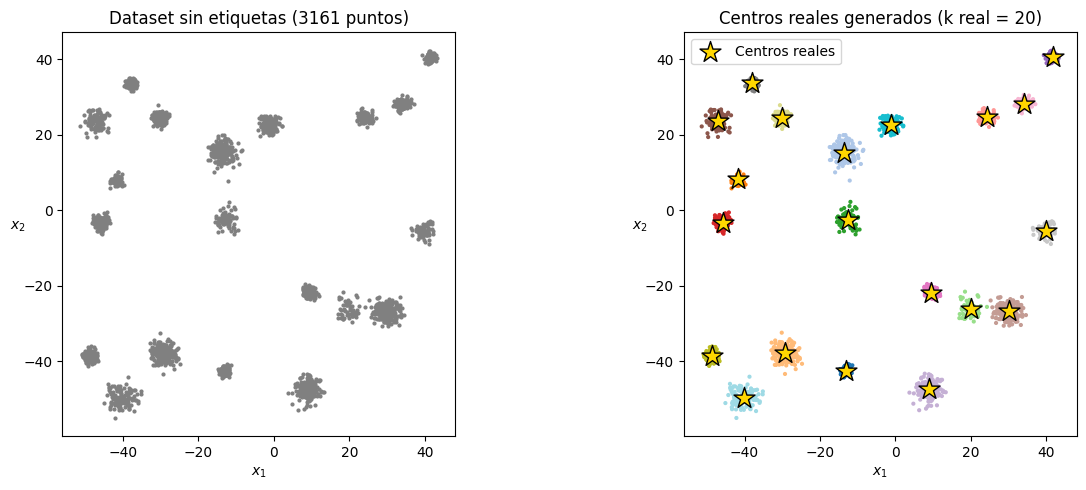

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(X[:, 0], X[:, 1], s=4, c='gray')
ax[0].set_title(f"Dataset sin etiquetas ({len(X)} puntos)")
ax[1].scatter(X[:, 0], X[:, 1], s=4, c=y_real, cmap="tab20")
ax[1].scatter(centros_reales[:, 0], centros_reales[:, 1], marker='*', s=250,
              c='gold', edgecolors='k', zorder=5, label="Centros reales")
ax[1].set_title(f"Centros reales generados (k real = {k})")
ax[1].legend()
for a in ax:
    a.set_xlabel("$x_1$")
    a.set_ylabel("$x_2$", rotation=0)
    a.set_aspect("equal")
plt.tight_layout()
plt.savefig("p1_01_dataset.png", dpi=120)
plt.show()

### el proceso iterativo de K-Means

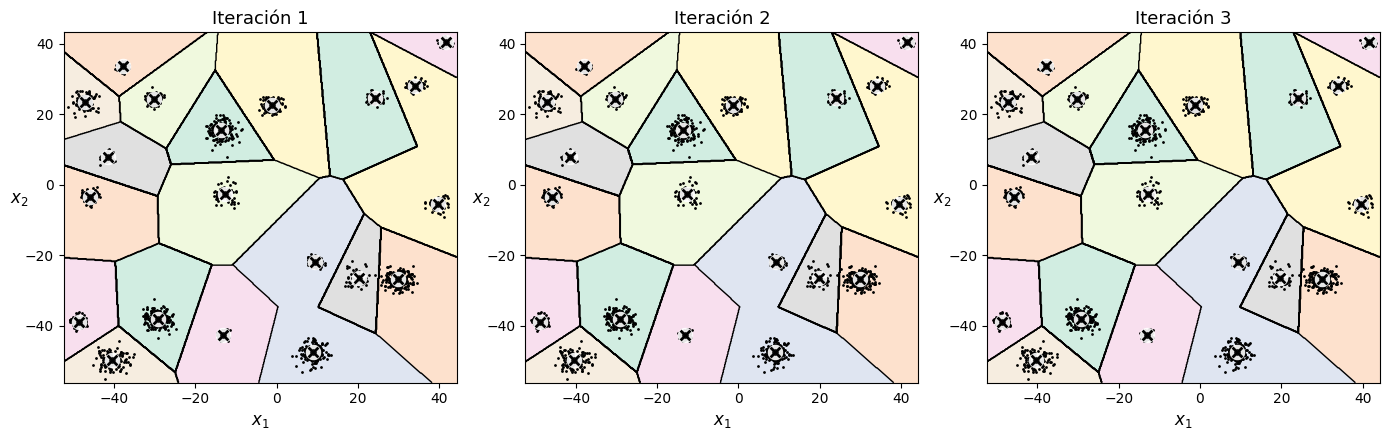

In [7]:
iters = [KMeans(n_clusters=k, init="k-means++", n_init=1, algorithm="lloyd",
                max_iter=m, random_state=1).fit(X) for m in (1, 2, 3)]

plt.figure(figsize=(14, 4.5))
for i, modelo in enumerate(iters):
    plt.subplot(1, 3, i + 1)
    plot_decision_boundaries(modelo, X)
    plt.title(f"Iteración {i + 1}", fontsize=13)
plt.tight_layout()
plt.savefig("p1_02_iteraciones.png", dpi=120)
plt.show()

### Aplicar K-Means: ubicación final de los centroides

In [8]:
kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
etiquetas = kmeans.fit_predict(X)
centroides = kmeans.cluster_centers_

### Número de puntos por centroide y los 5 más cercanos

In [9]:
conteo = np.bincount(etiquetas, minlength=k)

distancias = kmeans.transform(X)
cercanos = {}
for j in range(k):
    idx_cluster = np.where(etiquetas == j)[0]
    orden = np.argsort(distancias[idx_cluster, j])[:5]
    cercanos[j] = idx_cluster[orden]

### Resultados en texto

In [10]:
print(f"Inercia final: {kmeans.inertia_:.2f}")
for j in range(k):
    print(f"\nCentroide {j}: ({centroides[j, 0]:.2f}, {centroides[j, 1]:.2f})"
          f" | puntos: {conteo[j]}")
    for rango, i in enumerate(cercanos[j], start=1):
        print(f"   {rango}. índice {i:4d}  punto ({X[i, 0]:.2f}, {X[i, 1]:.2f})"
              f"  distancia {distancias[i, j]:.3f}")

err = [np.min(np.linalg.norm(centroides - c, axis=1)) for c in centros_reales]
print(f"\nError medio entre centros reales y centroides estimados: {np.mean(err):.3f}")

Inercia final: 10150.62

Centroide 0: (-47.11, 23.64) | puntos: 117
   1. índice 2038  punto (-47.20, 23.79)  distancia 0.179
   2. índice  512  punto (-47.31, 23.79)  distancia 0.244
   3. índice 2092  punto (-47.02, 23.28)  distancia 0.369
   4. índice  237  punto (-47.45, 23.88)  distancia 0.411
   5. índice 2895  punto (-47.32, 24.03)  distancia 0.443

Centroide 1: (-13.07, -42.66) | puntos: 231
   1. índice  420  punto (-13.04, -42.70)  distancia 0.048
   2. índice 2741  punto (-13.00, -42.68)  distancia 0.070
   3. índice  562  punto (-13.00, -42.61)  distancia 0.081
   4. índice  803  punto (-12.98, -42.70)  distancia 0.100
   5. índice 1852  punto (-13.09, -42.56)  distancia 0.100

Centroide 2: (34.01, 28.12) | puntos: 247
   1. índice 2032  punto (33.97, 28.10)  distancia 0.041
   2. índice 2004  punto (34.07, 28.16)  distancia 0.077
   3. índice 1461  punto (33.95, 28.20)  distancia 0.099
   4. índice 1288  punto (34.13, 28.12)  distancia 0.126
   5. índice 2731  punto (34.01

### Gráfico 3: resultado final

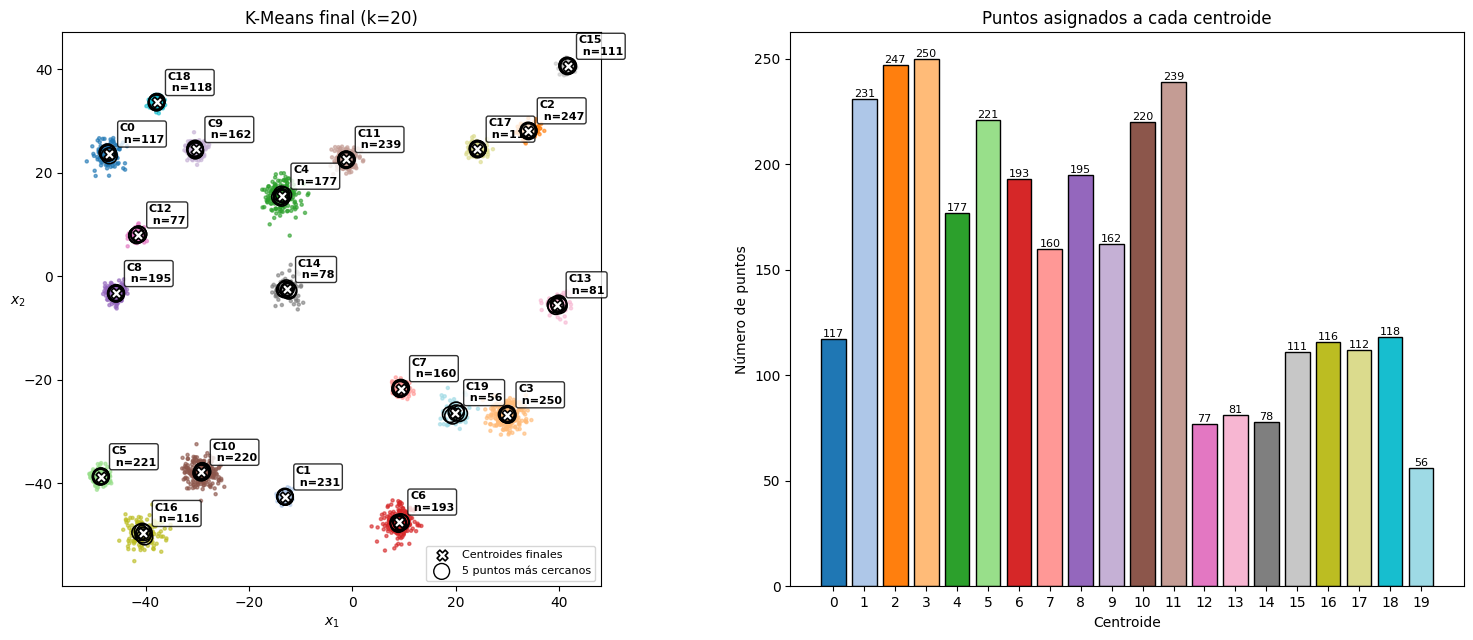

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})

a = ax[0]
a.scatter(X[:, 0], X[:, 1], c=etiquetas, cmap="tab20", s=5, alpha=0.6)
for j in range(k):
    idx = cercanos[j]
    a.scatter(X[idx, 0], X[idx, 1], s=130, facecolors='none',
              edgecolors='k', linewidths=1.2, zorder=6)
a.scatter(centroides[:, 0], centroides[:, 1], marker='X', s=60, c='white',
          edgecolors='k', linewidths=1.2, zorder=10, label="Centroides finales")
a.scatter([], [], s=130, facecolors='none', edgecolors='k', label="5 puntos más cercanos")
for j in range(k):
    a.annotate(f"C{j}\n n={conteo[j]}", centroides[j], textcoords="offset points",
               xytext=(8, 8), fontsize=8, fontweight="bold",
               bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8))
a.set_title(f"K-Means final (k={k})")
a.set_xlabel("$x_1$")
a.set_ylabel("$x_2$", rotation=0)
a.set_aspect("equal")
a.legend(loc="best", fontsize=8)

b = ax[1]
b.bar(range(k), conteo, color=[cmap(j % 20) for j in range(k)], edgecolor='k')
b.set_xticks(range(k))
b.set_xlabel("Centroide")
b.set_ylabel("Número de puntos")
b.set_title("Puntos asignados a cada centroide")
for j in range(k):
    b.text(j, conteo[j], str(conteo[j]), ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.savefig("p1_03_resultado_final.png", dpi=120)
plt.show()

### Gráfico 4: silueta vs número de clusters


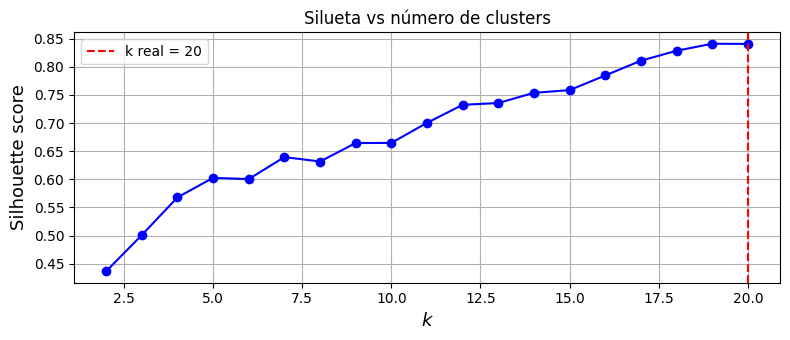

Mejor k según silueta: 19  (k real: 20)


In [12]:
if k >= 2:
    max_k = min(20, k + 5)
    ks = list(range(2, max_k + 1))
    modelos = [KMeans(n_clusters=kk, n_init=10, random_state=42).fit(X) for kk in ks]
    sil = [silhouette_score(X, m.labels_) for m in modelos]

    plt.figure(figsize=(8, 3.5))
    plt.plot(ks, sil, "bo-")
    plt.axvline(k, color="r", linestyle="--", label=f"k real = {k}")
    plt.xlabel("$k$", fontsize=13)
    plt.ylabel("Silhouette score", fontsize=13)
    plt.title("Silueta vs número de clusters")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig("p1_04_silueta.png", dpi=120)
    plt.show()
    print(f"Mejor k según silueta: {ks[int(np.argmax(sil))]}  (k real: {k})")
else:
    print("Con k=1 no se puede calcular la silueta (necesita al menos 2 clusters).")

### Gráfico 5: zoom por centroide

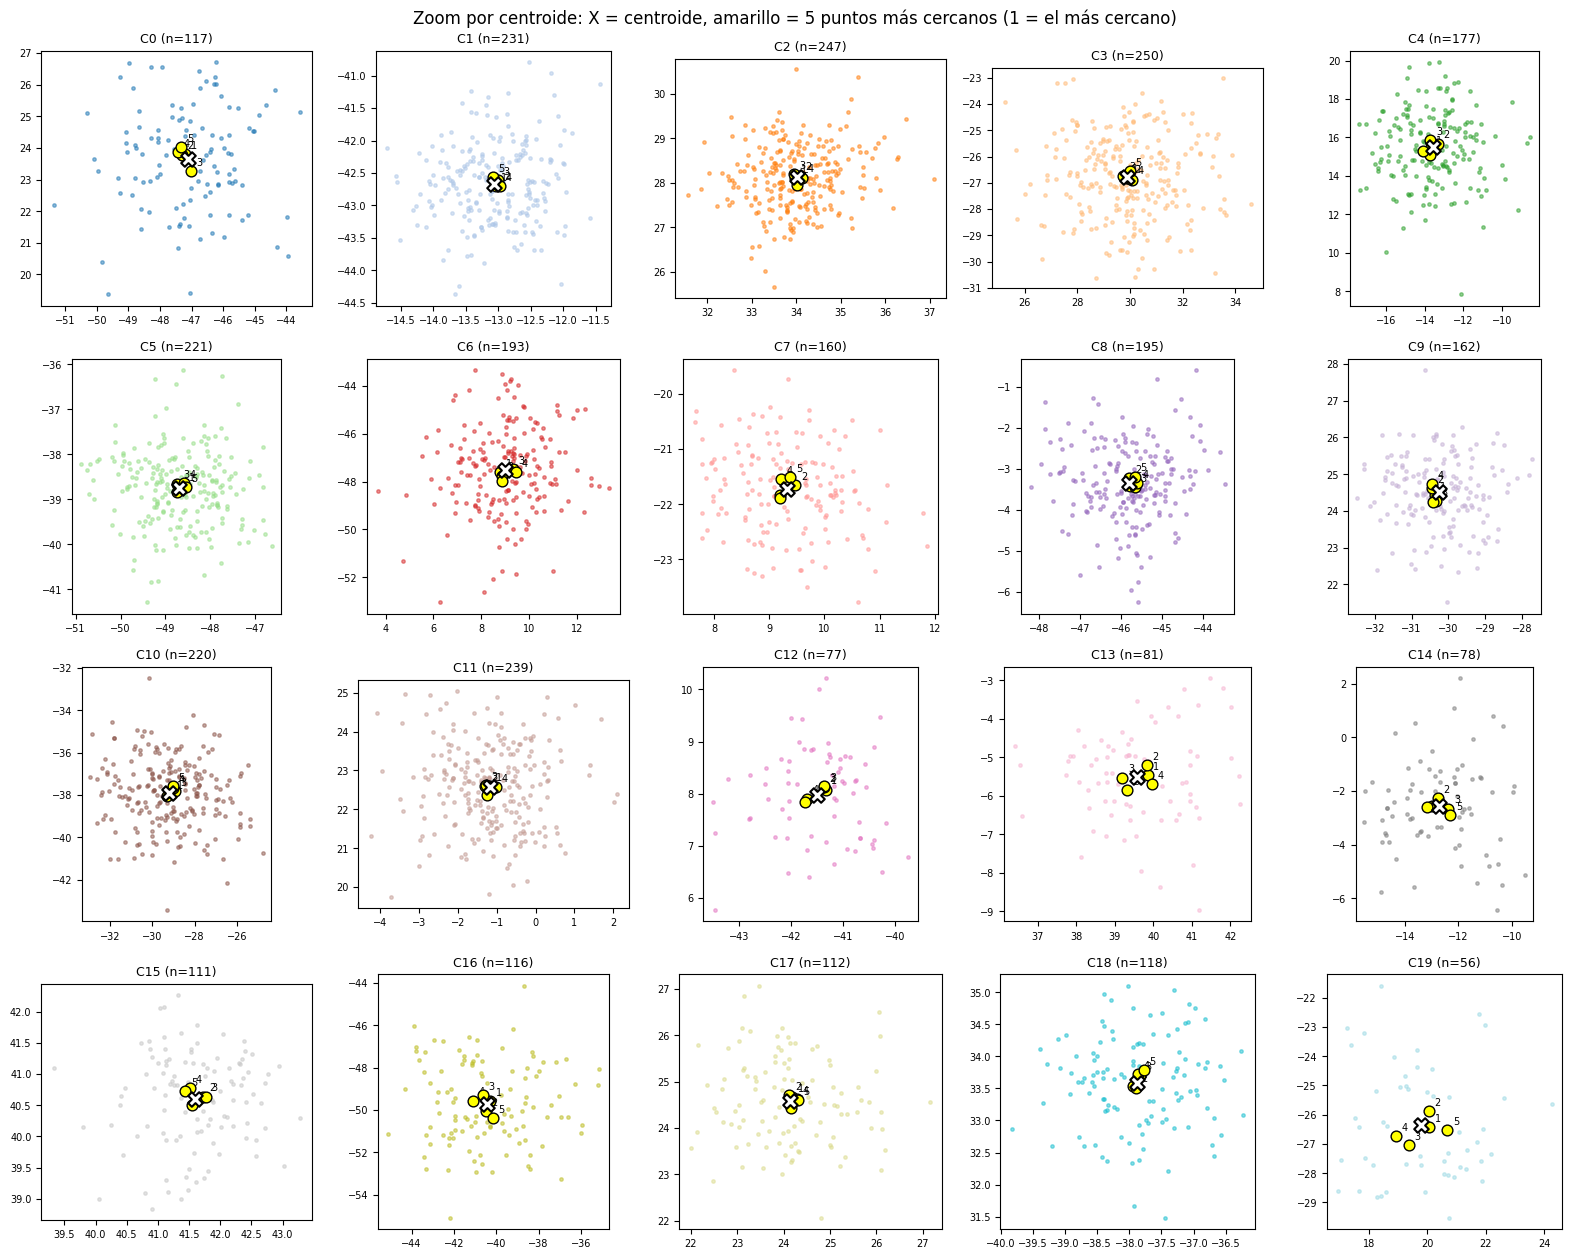

In [13]:
cols = min(5, k)
filas = int(np.ceil(k / cols))
fig, axs = plt.subplots(filas, cols, figsize=(3.2 * cols, 3.2 * filas), squeeze=False)
for j in range(k):
    a = axs[j // cols][j % cols]
    pts = X[etiquetas == j]
    a.scatter(pts[:, 0], pts[:, 1], s=6, color=cmap(j % 20), alpha=0.5)
    c5 = X[cercanos[j]]
    a.scatter(c5[:, 0], c5[:, 1], s=60, facecolors='yellow', edgecolors='k', zorder=5)
    for r, p in enumerate(c5, start=1):
        a.annotate(str(r), p, textcoords="offset points", xytext=(4, 4), fontsize=7)
    a.scatter(*centroides[j], marker='X', s=110, c='white', edgecolors='k',
              linewidths=1.5, zorder=6)
    a.set_title(f"C{j} (n={conteo[j]})", fontsize=9)
    a.set_aspect("equal")
    a.tick_params(labelsize=7)
for j in range(k, filas * cols):
    axs[j // cols][j % cols].axis("off")
plt.suptitle("Zoom por centroide: X = centroide, amarillo = 5 puntos más cercanos (1 = el más cercano)")
plt.tight_layout()
plt.savefig("p1_05_zoom_por_centroide.png", dpi=110)
plt.show()